# Plant Disease Detection Using YOLOv8

A beginner-friendly Google Colab notebook for training a YOLOv8n object-detection model on the small public Leaf Disease NSDSR dataset.

**Dataset:** [LibreYOLO/leaf-disease-nsdsr on Hugging Face](https://huggingface.co/datasets/LibreYOLO/leaf-disease-nsdsr)

The notebook downloads the dataset directly into Colab. No API key is required. It trains for **25 epochs**, evaluates the trained model, displays predictions, and downloads `best.pt`.


## 1. Check the runtime

In [1]:
import os
import random
from pathlib import Path

import numpy as np
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__)
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
if DEVICE == "cpu":
    print("Tip: enable a GPU in Runtime > Change runtime type for faster training.")

PyTorch: 2.14.1+cpu
Device: CPU
Tip: enable a GPU in Runtime > Change runtime type for faster training.


## 2. Install the required libraries

In [2]:
!pip -q install ultralytics huggingface_hub pyyaml pandas matplotlib pillow

## 3. Import libraries

In [3]:
import yaml
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from huggingface_hub import snapshot_download
from ultralytics import YOLO

print("Imports completed.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Imports completed.


## 4. Download the dataset

In [4]:
DATASET_DIR = Path("/content/leaf-disease-nsdsr")

snapshot_download(
    repo_id="LibreYOLO/leaf-disease-nsdsr",
    repo_type="dataset",
    local_dir=str(DATASET_DIR)
)

yaml_files = list(DATASET_DIR.rglob("data.yaml"))
if not yaml_files:
    raise FileNotFoundError("Could not find data.yaml in the downloaded dataset.")

DATA_YAML = yaml_files[0]
print("Dataset folder:", DATASET_DIR)
print("Dataset configuration:", DATA_YAML)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5007 files:   0%|          | 0/5007 [00:00<?, ?it/s]

Dataset folder: /content/leaf-disease-nsdsr
Dataset configuration: /content/leaf-disease-nsdsr/data.yaml


## 5. Read class names and dataset paths

In [5]:
with open(DATA_YAML, "r") as file:
    data = yaml.safe_load(file)

names = data.get("names", [])
if isinstance(names, dict):
    names = [names[key] for key in sorted(names, key=lambda x: int(x))]

if not names:
    raise ValueError("No class names were found in data.yaml.")

print("Number of classes:", len(names))
print("Classes:", names)

# Resolve relative dataset paths using the dataset folder.
yaml_root = Path(data.get("path", DATA_YAML.parent))
if not yaml_root.is_absolute():
    yaml_root = (DATA_YAML.parent / yaml_root).resolve()

def resolve_split(split_name):
    value = data.get(split_name)
    if value is None:
        return None

    paths = value if isinstance(value, list) else [value]
    resolved = []
    for item in paths:
        path = Path(item)
        if not path.is_absolute():
            path = yaml_root / path
        resolved.append(path.resolve())

    return resolved[0] if len(resolved) == 1 else resolved

train_path = resolve_split("train")
val_path = resolve_split("val") or resolve_split("valid")
test_path = resolve_split("test")

if train_path is None or val_path is None:
    raise ValueError("The dataset YAML must contain train and val (or valid) paths.")

# Use absolute paths so YOLO can find the downloaded images.
data["path"] = str(yaml_root)
data["train"] = str(train_path)
data["val"] = str(val_path)
if test_path is not None:
    data["test"] = str(test_path)

NORMALIZED_YAML = Path("/content/plant_disease_data.yaml")
with open(NORMALIZED_YAML, "w") as file:
    yaml.safe_dump(data, file, sort_keys=False)

DATA_YAML = NORMALIZED_YAML
print("Train:", train_path)
print("Validation:", val_path)
print("Test:", test_path)

Number of classes: 3
Classes: ['mildew', 'rose_P01', 'rose_R02']
Train: /content/leaf-disease-nsdsr/train/images
Validation: /content/leaf-disease-nsdsr/valid/images
Test: /content/leaf-disease-nsdsr/test/images


## 6. Count images in each split

In [6]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def count_images(folder):
    if folder is None:
        return 0
    if isinstance(folder, list):
        return sum(count_images(item) for item in folder)
    if not Path(folder).exists():
        return 0
    return sum(1 for item in Path(folder).rglob("*") if item.suffix.lower() in IMAGE_EXTENSIONS)

train_count = count_images(train_path)
val_count = count_images(val_path)
test_count = count_images(test_path)

print("Training images:", train_count)
print("Validation images:", val_count)
print("Test images:", test_count)

if train_count == 0 or val_count == 0:
    raise FileNotFoundError("Training or validation images were not found. Check data.yaml paths.")

Training images: 1589
Validation images: 616
Test images: 296


## 7. Display sample training images

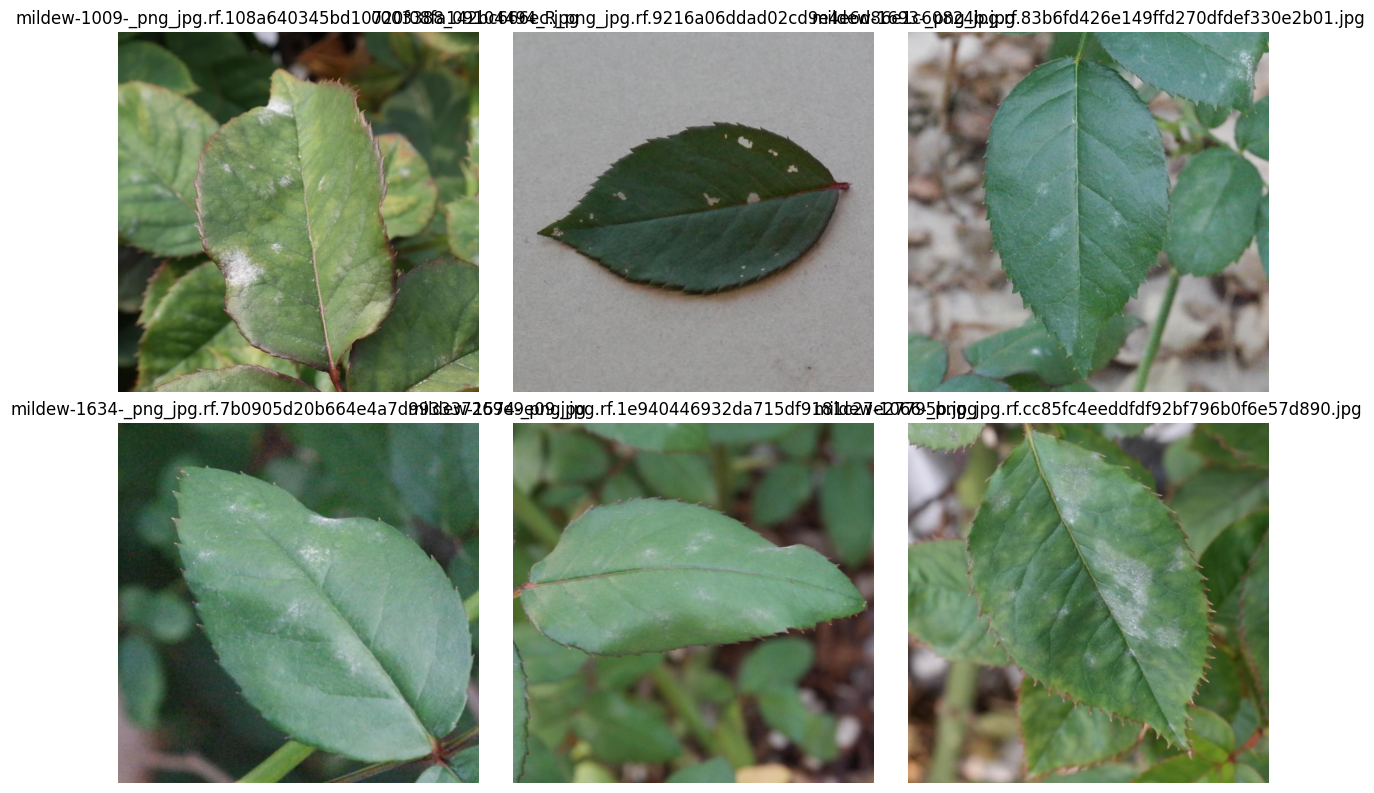

In [7]:
train_folder = Path(train_path[0] if isinstance(train_path, list) else train_path)
sample_paths = [p for p in train_folder.rglob("*") if p.suffix.lower() in IMAGE_EXTENSIONS][:6]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, image_path in zip(axes.flat, sample_paths):
    ax.imshow(Image.open(image_path).convert("RGB"))
    ax.set_title(image_path.name)
    ax.axis("off")

for ax in axes.flat[len(sample_paths):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 8. Load the pretrained YOLOv8n model

In [8]:
model = YOLO("yolov8n.pt")
print("YOLOv8n pretrained model loaded.")

YOLOv8n pretrained model loaded.


## 9. Train the model

The notebook uses **25 epochs**.

In [9]:
EPOCHS = 25
IMAGE_SIZE = 640
BATCH_SIZE = 8

train_results = model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=2,
    seed=SEED,
    project="/content/Plant_Disease",
    name="YOLOv8n_Plant_Disease",
    exist_ok=True,
    patience=10,
    plots=True
)

RUN_DIR = Path(train_results.save_dir)
BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"

print("Training output:", RUN_DIR)
print("Best weights found:", BEST_WEIGHTS.exists())

if not BEST_WEIGHTS.exists():
    raise FileNotFoundError("Training finished but best.pt was not created.")

Ultralytics 8.4.216 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/plant_disease_data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLOv8n_Plant_Disease, nbs=64, nms=None, opset=None, o

## 10. View training results

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
20,21,24972.8,1.24360,0.86618,1.24887,0.69631,0.66819,0.66241,0.37813,1.35694,1.30910,1.34636,0.000297,0.000297,0.000297
21,22,26162.0,1.23785,0.84216,1.23908,0.71728,0.58275,0.64944,0.36683,1.35290,1.34476,1.34313,0.000241,0.000241,0.000241
22,23,27348.4,1.19913,0.80123,1.21326,0.68631,0.63196,0.65790,0.37362,1.35703,1.30809,1.34776,0.000184,0.000184,0.000184
23,24,28537.7,1.19226,0.78968,1.21841,0.64654,0.66007,0.66261,0.37836,1.36001,1.32473,1.34695,0.000127,0.000127,0.000127
24,25,29726.2,1.18933,0.78443,1.20827,0.70329,0.62478,0.66318,0.38128,1.35153,1.29595,1.34527,0.000071,0.000071,0.000071


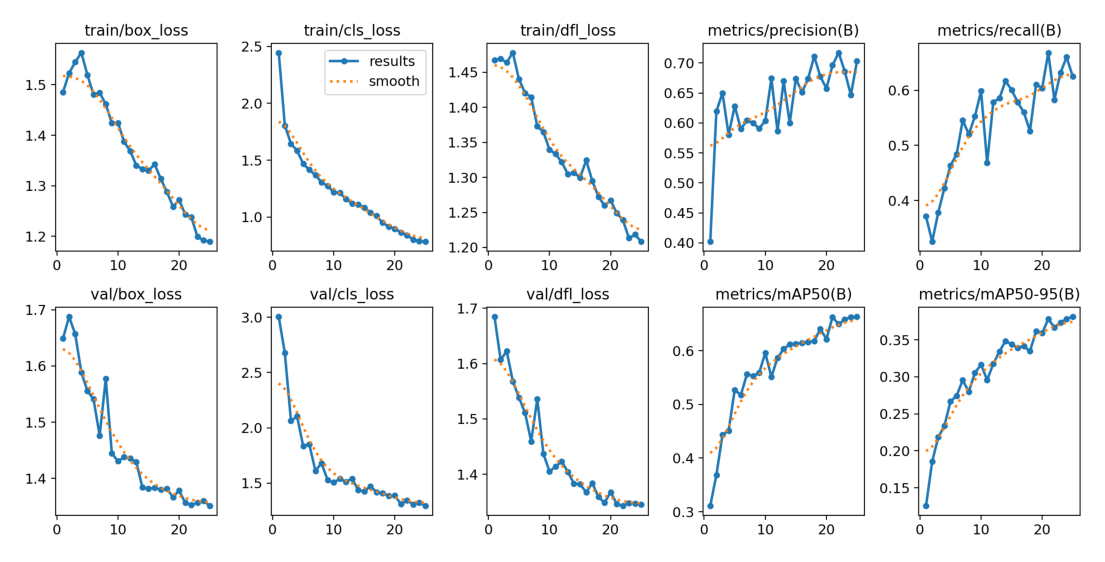

In [10]:
results_csv = RUN_DIR / "results.csv"
results_png = RUN_DIR / "results.png"

if results_csv.exists():
    results_table = pd.read_csv(results_csv)
    display(results_table.tail())

if results_png.exists():
    plt.figure(figsize=(14, 8))
    plt.imshow(Image.open(results_png))
    plt.axis("off")
    plt.show()
else:
    print("Training plot was not found.")

## 11. Load the best trained weights

In [11]:
best_model = YOLO(str(BEST_WEIGHTS))
print("Best model loaded successfully.")

Best model loaded successfully.


## 12. Evaluate the model

In [12]:
evaluation_split = "test" if test_count > 0 else "val"
print("Evaluation split:", evaluation_split)

metrics = best_model.val(
    data=str(DATA_YAML),
    split=evaluation_split,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    plots=True
)

precision = float(metrics.box.mp)
recall = float(metrics.box.mr)
map50 = float(metrics.box.map50)
map5095 = float(metrics.box.map)

print("\nEvaluation results")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"mAP50: {map50:.4f}")
print(f"mAP50-95: {map5095:.4f}")

Evaluation split: test
Ultralytics 8.4.216 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 7.1±2.0 MB/s, size: 31.9 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/leaf-disease-nsdsr/test/labels... 296 images, 0 backgrounds, 67 corrupt: 100% ━━━━━━━━━━━━ 296/296 520.3it/s 0.6s
val: /content/leaf-disease-nsdsr/test/images/mildew-122-_png_jpg.rf.1afbc102aa1670efca4d794184e2d21d.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /content/leaf-disease-nsdsr/test/images/mildew-1220-_png_jpg.rf.8120ee759425fd443be7130348f59e53.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /content/leaf-disease-nsdsr/test/images/mildew-1239-_png_jpg.rf.9d23c7d675d1dfcfb55f67e

## 13. Display evaluation plots

In [ ]:
validation_dir = Path(metrics.save_dir)
plot_files = [
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "PR_curve.png",
    "F1_curve.png",
    "P_curve.png",
    "R_curve.png"
]

for filename in plot_files:
    plot_path = validation_dir / filename
    if plot_path.exists():
        plt.figure(figsize=(8, 6))
        plt.imshow(Image.open(plot_path))
        plt.title(filename)
        plt.axis("off")
        plt.show()

## 14. Make a prediction on an image

In [ ]:
prediction_folder = Path(test_path if test_count > 0 else val_path)
prediction_images = [
    p for p in prediction_folder.rglob("*")
    if p.suffix.lower() in IMAGE_EXTENSIONS
]

if not prediction_images:
    raise FileNotFoundError("No images were found for prediction.")

sample_image = prediction_images[0]
prediction = best_model.predict(
    source=str(sample_image),
    conf=0.25,
    imgsz=IMAGE_SIZE,
    verbose=False
)

plt.figure(figsize=(10, 8))
plt.imshow(prediction[0].plot()[:, :, ::-1])
plt.title("Plant Disease Detection")
plt.axis("off")
plt.show()

print("Image used:", sample_image)

## 15. Show detected classes and confidence

In [ ]:
boxes = prediction[0].boxes
detections = []

if boxes is not None:
    for box in boxes:
        class_id = int(box.cls.item())
        confidence = float(box.conf.item())
        detections.append({
            "Class": best_model.names[class_id],
            "Confidence": round(confidence, 4),
            "Confidence (%)": round(confidence * 100, 2)
        })

if detections:
    display(pd.DataFrame(detections))
else:
    print("No objects detected at confidence 0.25.")

## 16. Compare confidence thresholds

In [16]:
for threshold in [0.15, 0.25, 0.50]:
    output = best_model.predict(
        source=str(sample_image),
        conf=threshold,
        imgsz=IMAGE_SIZE,
        verbose=False
    )
    box_count = len(output[0].boxes) if output[0].boxes is not None else 0
    print(f"Threshold {threshold:.2f}: {box_count} detections")

Threshold 0.15: 1 detections
Threshold 0.25: 1 detections
Threshold 0.50: 1 detections


## 17. Export and download the trained model

In [17]:
import shutil

EXPORT_MODEL = Path("/content/best.pt")
shutil.copy2(BEST_WEIGHTS, EXPORT_MODEL)

print("Model saved to:", EXPORT_MODEL)
print("Model size (MB):", round(EXPORT_MODEL.stat().st_size / (1024 * 1024), 2))

Model saved to: /content/best.pt
Model size (MB): 6.2


In [18]:
from google.colab import files
files.download(str(EXPORT_MODEL))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 18. Results summary

After the notebook finishes, record the actual values printed in Section 12.

| Metric | Your result |
|---|---|
| Number of classes | Printed in Section 5 |
| Training epochs | 25 (unless training was stopped early) |
| Precision | 0.8663 |
| Recall | 0.8415 |
| mAP50 | 0.8837
| mAP50-95 | 0.6329 |
| Evaluation split | Test or validation, as printed |



## 19. Load the model in your app

The Streamlit app needs the trained weights (`best.pt`) saved in Section 17. First, install Streamlit and check that the file loads correctly and knows its classes.

In [19]:
!pip -q install "streamlit>=1.50"

from ultralytics import YOLO

APP_MODEL_PATH = Path("/content/best.pt")
if not APP_MODEL_PATH.exists():
    raise FileNotFoundError("best.pt not found. Run Section 17 first.")

app_model = YOLO(str(APP_MODEL_PATH))
print("Model loaded for the app.")
print("Classes:", app_model.names)

Model loaded for the app.
Classes: {0: 'mildew', 1: 'rose_P01', 2: 'rose_R02'}


## 20. Build the Streamlit interface

The cell below writes `app.py`. The app loads the model once (`st.cache_resource`) and lets the user:

- **Upload an image** (JPG, PNG, BMP, WEBP)
- **Adjust a confidence threshold** with a slider
- **See the image with bounding boxes and labels**
- **See a list of detected objects** with their confidence scores

In [20]:
%%writefile /content/app.py
from pathlib import Path

import pandas as pd
import streamlit as st
from PIL import Image, ImageOps
from ultralytics import YOLO

# ------------------------------------------------------------------
# Page setup
# ------------------------------------------------------------------
st.set_page_config(page_title="Plant Disease Detection", page_icon="🌿", layout="wide")

# Trained weights exported in Section 17 of the notebook.
# Falls back to a best.pt placed next to this file (for running locally).
MODEL_PATH = Path("/content/best.pt")
if not MODEL_PATH.exists():
    MODEL_PATH = Path(__file__).parent / "best.pt"

IMAGE_SIZE = 640


# ------------------------------------------------------------------
# Load the model (cached, so it is loaded only once per session)
# ------------------------------------------------------------------
@st.cache_resource(show_spinner="Loading model...")
def load_model(path: str) -> YOLO:
    return YOLO(path)


if not MODEL_PATH.exists():
    st.error(f"Model file not found: `{MODEL_PATH}`. Run Section 17 of the notebook to create best.pt.")
    st.stop()

model = load_model(str(MODEL_PATH))

# ------------------------------------------------------------------
# Interface
# ------------------------------------------------------------------
st.title("🌿 Plant Disease Detection")
st.caption("Upload a leaf image and the YOLOv8n model will locate and label diseases.")

with st.sidebar:
    st.header("Settings")
    confidence = st.slider(
        "Confidence threshold",
        min_value=0.05,
        max_value=0.95,
        value=0.25,
        step=0.05,
        help="Detections below this confidence are hidden.",
    )
    st.markdown("**Classes the model knows:**")
    for class_name in model.names.values():
        st.markdown(f"- {class_name}")

uploaded_file = st.file_uploader("Upload an image", type=["jpg", "jpeg", "png", "bmp", "webp"])

if uploaded_file is None:
    st.info("Upload an image to start.")
    st.stop()

# Open the image, fix phone-camera rotation, and force 3 colour channels.
image = ImageOps.exif_transpose(Image.open(uploaded_file)).convert("RGB")

with st.spinner("Running detection..."):
    result = model.predict(source=image, conf=confidence, imgsz=IMAGE_SIZE, verbose=False)[0]

# Build the list of detections.
detections = []
for box in result.boxes:
    score = float(box.conf.item())
    detections.append(
        {
            "Class": model.names[int(box.cls.item())],
            "Confidence": round(score, 4),
            "Confidence (%)": round(score * 100, 2),
        }
    )

left, right = st.columns([3, 2])

with left:
    st.subheader("Detection result")
    # result.plot() draws boxes + labels and returns a BGR array; flip to RGB for display.
    st.image(result.plot()[:, :, ::-1], width="stretch")

with right:
    st.subheader("Detected objects")
    if detections:
        table = pd.DataFrame(detections).sort_values("Confidence", ascending=False).reset_index(drop=True)
        table.index += 1
        st.metric("Total detections", len(table))
        st.dataframe(table)
        st.markdown("**Count per class**")
        st.bar_chart(table["Class"].value_counts())
    else:
        st.warning(f"No objects detected at a confidence of {confidence:.2f}. Try lowering the threshold.")

Writing /content/app.py


## 21. Run the app

In [21]:
import re
import subprocess
import time

# Stop any earlier copies so the cell can be re-run safely.
!pkill -f "streamlit run" 2>/dev/null
!pkill -f cloudflared 2>/dev/null

# Download the Cloudflare tunnel client (one-time).
!wget -q -nc https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /content/cloudflared
!chmod +x /content/cloudflared

# Start Streamlit in the background.
subprocess.Popen(
    ["streamlit", "run", "/content/app.py",
     "--server.port", "8501", "--server.headless", "true"],
    stdout=open("/content/streamlit.log", "w"), stderr=subprocess.STDOUT,
)
time.sleep(5)

# Open a public tunnel to the app and print its link.
tunnel = subprocess.Popen(
    ["/content/cloudflared", "tunnel", "--url", "http://localhost:8501"],
    stdout=open("/content/tunnel.log", "w"), stderr=subprocess.STDOUT,
)

public_url = None
for _ in range(30):
    time.sleep(1)
    match = re.search(r"https://[-a-z0-9]+\.trycloudflare\.com", open("/content/tunnel.log").read())
    if match:
        public_url = match.group(0)
        break

print("Open your app here:", public_url or "link not ready - check /content/tunnel.log")

^C
^C
Open your app here: https://pens-paintings-rider-hollywood.trycloudflare.com
